Practice Question: Cat and Dog Image Classification 

Task: Create a Deep Learning project using TensorFlow and Keras to classify images as Cat or Dog

Write a Python program that downloads the Cats and Dogs dataset, loads training and validation images, resizes them to 128 × 128 pixels, and builds a CNN model using convolutional, max-pooling, flatten, dense, and dropout layers. Compile the model using the Adam optimizer and binary cross-entropy loss, then train it for 5 epochs. Plot the training and validation accuracy using Matplotlib. Finally, create a file-selection dialog using Tkinter that allows users to select up to 5 images from their computer and displays each image with its predicted class and confidence percentage.

Hints

1. Dataset: Use tf.keras.utils.get_file() to download and extract the dataset.


2. Load Images: Use tf.keras.utils.image_dataset_from_directory().


3. CNN Architecture: Use Conv2D, MaxPooling2D, Flatten, Dense, and Dropout.


4. Normalize Images: Use layers.Rescaling(1./255).


5. Compile Model: Use optimizer="adam", loss="binary_crossentropy", and metrics=["accuracy"].


6. Train Model: Use model.fit() with epochs=5.


7. Plot Accuracy: Access history.history["accuracy"] and history.history["val_accuracy"].


8. Select Images: Use filedialog.askopenfilenames() and limit the selection to five images.


9. Prepare Images: Use load_img(), img_to_array(), and np.expand_dims().


10. Predict Classes: Use model.predict() and a threshold of 0.5 to distinguish between cats and dogs.

In [1]:
# 1. Import libraries
import os
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image


In [2]:
# 2. Download the dataset
# If KaggleHub is not installed, run: %pip install kagglehub
import kagglehub

path = kagglehub.dataset_download("bhavikjikadara/dog-and-cat-classification-dataset")
dataset_path = os.path.join(path, "PetImages")
print("Dataset downloaded")


Dataset downloaded


In [3]:
# 3. Clean and convert the images
clean_path = os.path.join(path, "PetImages_Clean")
os.makedirs(clean_path, exist_ok=True)

for folder in ["Cat", "Dog"]:
    source_folder = os.path.join(dataset_path, folder)
    target_folder = os.path.join(clean_path, folder)
    os.makedirs(target_folder, exist_ok=True)

    for file in os.listdir(source_folder):
        try:
            img = Image.open(os.path.join(source_folder, file))
            img = img.convert("RGB")
            img.save(os.path.join(target_folder, file + ".jpg"), "JPEG")
        except Exception:
            continue

    print(folder, "images cleaned")

print("Clean dataset ready!")


Cat images cleaned


C:\Users\Shakti\anaconda3\Lib\site-packages\PIL\TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Dog images cleaned
Clean dataset ready!


In [5]:
# 4. Load training and validation images
train_data = tf.keras.utils.image_dataset_from_directory(
    clean_path,
    image_size=(128, 128),
    batch_size=32,
    label_mode="binary",
    validation_split=0.2,
    subset="training",
    seed=123
)

validation_data = tf.keras.utils.image_dataset_from_directory(
    clean_path,
    image_size=(128, 128),
    batch_size=32,
    label_mode="binary",
    validation_split=0.2,
    subset="validation",
    seed=123
)


Found 24998 files belonging to 2 classes.
Using 19999 files for training.
Found 24998 files belonging to 2 classes.
Using 4999 files for validation.


In [6]:
# 5. Build the CNN model
model = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./255, input_shape=(128, 128, 3)),
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation="sigmoid")
])


C:\Users\Shakti\anaconda3\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [7]:
# 6. Compile the model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


In [8]:
# 7. Train the model
history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=3
)


Epoch 1/3


C:\Users\Shakti\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


625/625 ━━━━━━━━━━━━━━━━━━━━ 246s 389ms/step - accuracy: 0.6376 - loss: 0.6544 - val_accuracy: 0.7087 - val_loss: 0.5691
Epoch 2/3
625/625 ━━━━━━━━━━━━━━━━━━━━ 257s 381ms/step - accuracy: 0.7412 - loss: 0.5232 - val_accuracy: 0.7524 - val_loss: 0.5030
Epoch 3/3
625/625 ━━━━━━━━━━━━━━━━━━━━ 259s 413ms/step - accuracy: 0.8004 - loss: 0.4308 - val_accuracy: 0.7560 - val_loss: 0.5234


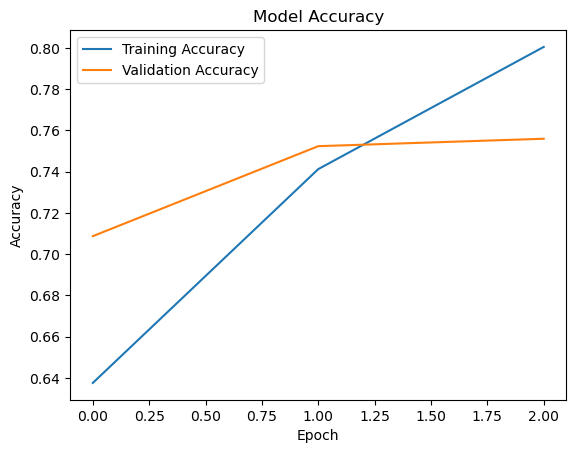

In [9]:
# 8. Plot training and validation accuracy
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


In [4]:
# 9. Select up to five images and predict
import tkinter as tk
from tkinter import filedialog
from tensorflow.keras.utils import load_img, img_to_array

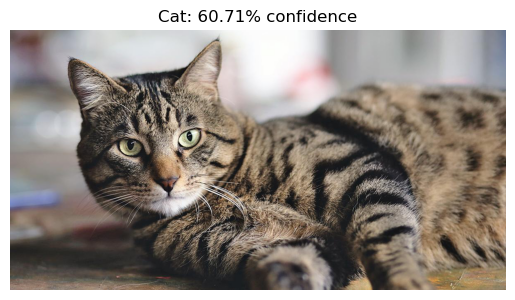

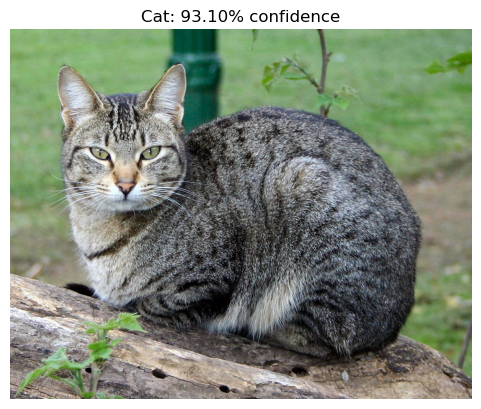

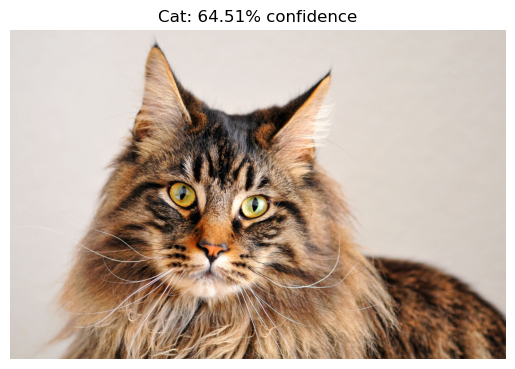

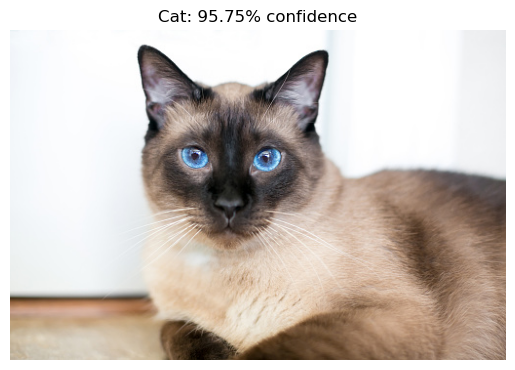

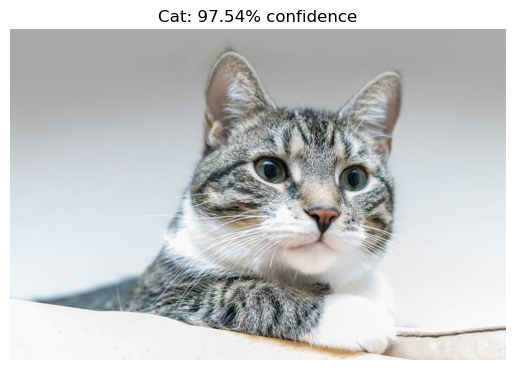

In [11]:
root = tk.Tk()
root.withdraw()
root.attributes("-topmost", True)
file_paths = filedialog.askopenfilenames(
    title="Select up to 5 cat or dog images",
    filetypes=[("Image files", "*.jpg *.jpeg *.png *.bmp *.webp")]
)
root.destroy()

for file_path in file_paths[:5]:
    img = load_img(file_path, target_size=(128, 128))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array, verbose=0)[0][0]

    if prediction >= 0.5:
        result = "Dog"
        confidence = prediction * 100
    else:
        result = "Cat"
        confidence = (1 - prediction) * 100

    plt.figure()
    plt.imshow(load_img(file_path))
    plt.title(f"{result}: {confidence:.2f}% confidence")
    plt.axis("off")
    plt.show()

if not file_paths:
    print("No images selected.")


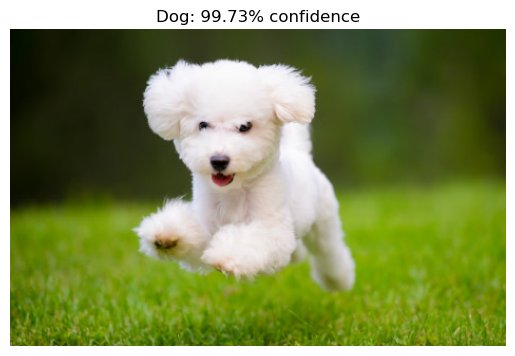

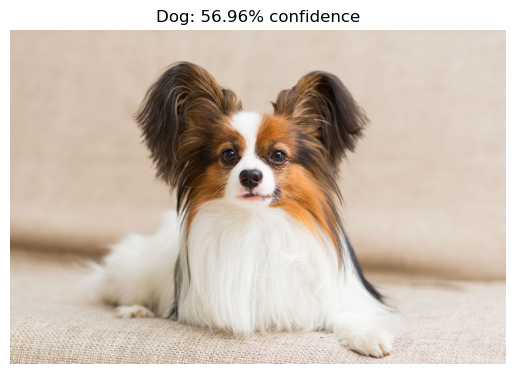

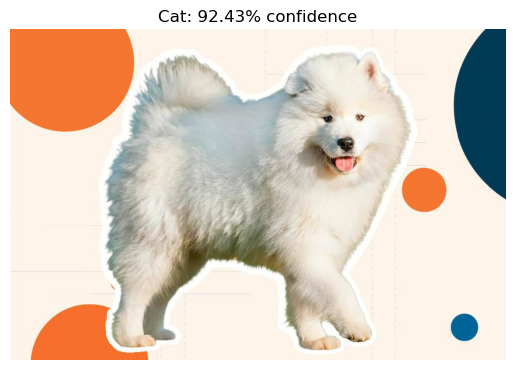

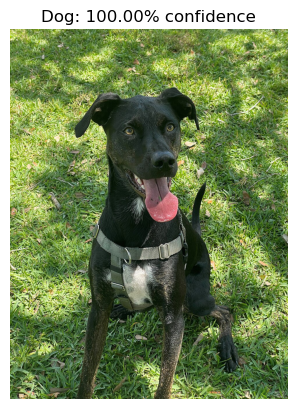

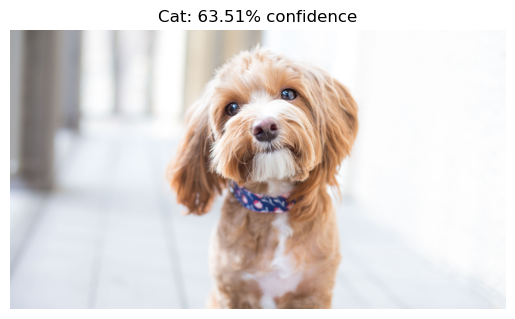

In [13]:
root = tk.Tk()
root.withdraw()
root.attributes("-topmost", True)
file_paths = filedialog.askopenfilenames(
    title="Select up to 5 cat or dog images",
    filetypes=[("Image files", "*.jpg *.jpeg *.png *.bmp *.webp")]
)
root.destroy()

for file_path in file_paths[:5]:
    img = load_img(file_path, target_size=(128, 128))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array, verbose=0)[0][0]

    if prediction >= 0.5:
        result = "Dog"
        confidence = prediction * 100
    else:
        result = "Cat"
        confidence = (1 - prediction) * 100

    plt.figure()
    plt.imshow(load_img(file_path))
    plt.title(f"{result}: {confidence:.2f}% confidence")
    plt.axis("off")
    plt.show()

if not file_paths:
    print("No images selected.")


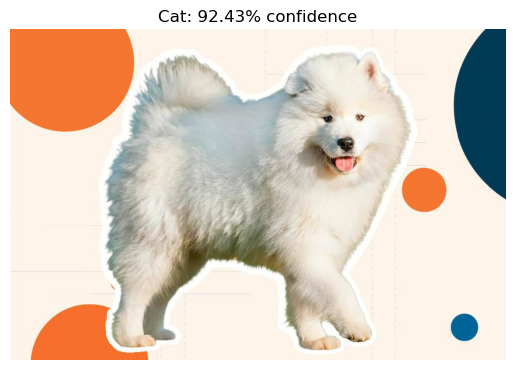

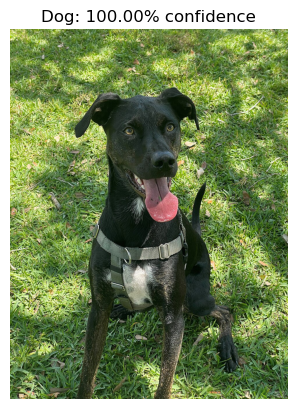

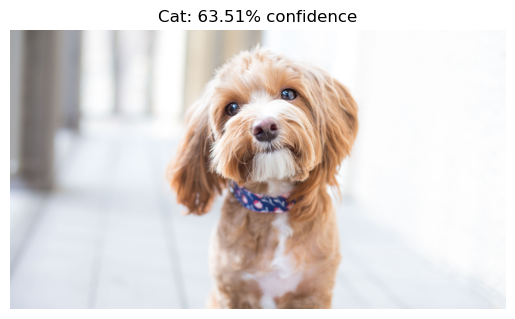

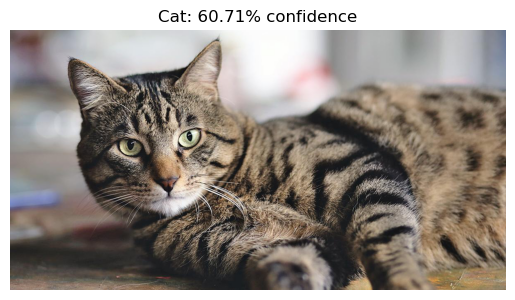

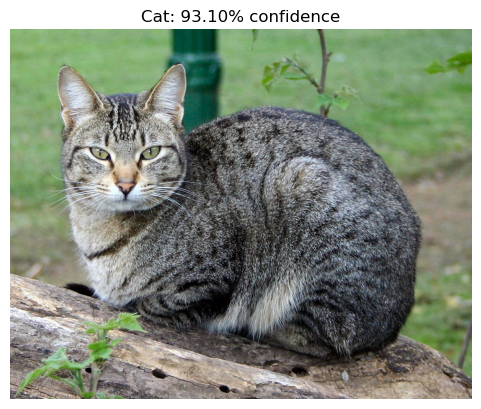

In [14]:
root = tk.Tk()
root.withdraw()
root.attributes("-topmost", True)
file_paths = filedialog.askopenfilenames(
    title="Select up to 5 cat or dog images",
    filetypes=[("Image files", "*.jpg *.jpeg *.png *.bmp *.webp")]
)
root.destroy()

for file_path in file_paths[:5]:
    img = load_img(file_path, target_size=(128, 128))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array, verbose=0)[0][0]

    if prediction >= 0.5:
        result = "Dog"
        confidence = prediction * 100
    else:
        result = "Cat"
        confidence = (1 - prediction) * 100

    plt.figure()
    plt.imshow(load_img(file_path))
    plt.title(f"{result}: {confidence:.2f}% confidence")
    plt.axis("off")
    plt.show()

if not file_paths:
    print("No images selected.")
